# Taller RFM — Respuesta guiada (`datos_de_ventas.csv`)

Este notebook replica la **logica del modelo RFM** del cuaderno `Modelo_RFM_20260326 (2).ipynb`, adaptada a la base **`datos_de_ventas.csv`** (ventas minoristas con columnas en espanol sin tildes).

**Equivalencias con el modelo de clase**

| Rol en el modelo original | En `datos_de_ventas.csv` |
|---------------------------|--------------------------|
| Cliente (`cliente_documento`) | `ID_Cliente` |
| Fecha transaccion (`id_tiempo`) | `Fecha` (YYYY-MM-DD) |
| Frecuencia (`cant_formularios` sumada) | Numero de **transacciones** (filas) por cliente |
| Monto (`vlr_transaccion` sumado) | `Importe_Total` sumado |
| Filtro por producto | `Categoria_Producto` o `"TODOS"` |
| Genero / edad | `Genero`, `Edad` |

**Pasos:** carga y revision → preparacion de fechas → analisis descriptivo → funcion `ModeloRFM_retail` (mismos pesos y segmentos que en clase) → resultados y graficos.

## 1. Configuracion e importaciones

In [12]:
import datetime as dt
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from IPython.display import display

%matplotlib inline
plt.style.use("ggplot")
sns.set_theme(style="whitegrid")

_aqui = Path.cwd()
_candidatos = [
    _aqui / "datos_de_ventas.csv",
    _aqui.parent / "Insumos" / "datos_de_ventas.csv",
    _aqui / "ML_Finanzas" / "Clases" / "Talleres" / "RFM" / "Insumos" / "datos_de_ventas.csv",
]
RUTA_CSV = next((p for p in _candidatos if p.is_file()), None)
if RUTA_CSV is None:
    raise FileNotFoundError(
        "No se encontro datos_de_ventas.csv. Coloca el kernel en Notebook/ o en Insumos/ o ajusta RUTA_CSV."
    )
print("Archivo:", RUTA_CSV.resolve())

Archivo: C:\Users\owoc9\Documents\U Javeriana\2026-I\ML_Finanzas\Clases\Talleres\RFM\Insumos\datos_de_ventas.csv


## 2. Carga y exploracion inicial

In [13]:
df = pd.read_csv(RUTA_CSV)
print("Dimensiones:", df.shape)
print(df.dtypes)
df.head()

Dimensiones: (1000, 9)
ID_Transaccion        int64
Fecha                   str
ID_Cliente              str
Genero                  str
Edad                  int64
Categoria_Producto      str
Cantidad              int64
Precio_Unitario       int64
Importe_Total         int64
dtype: object


,ID_Transaccion,Fecha,ID_Cliente,Genero,Edad,Categoria_Producto,Cantidad,Precio_Unitario,Importe_Total
0,1,2023-11-24,CUST001,Masculino,34,Belleza,3,50,150
1,2,2023-02-27,CUST002,Femenino,26,Ropa,2,500,1000
2,3,2023-01-13,CUST003,Masculino,50,Electronica,1,30,30
3,4,2023-05-21,CUST004,Masculino,37,Ropa,1,500,500
4,5,2023-05-06,CUST005,Masculino,30,Belleza,2,50,100


## 3. Preparacion: fechas y columnas esperadas

Se convierte `Fecha` a datetime y se comprueba que existan las columnas necesarias para RFM.

In [14]:
requeridas = [
    "ID_Transaccion",
    "Fecha",
    "ID_Cliente",
    "Genero",
    "Edad",
    "Categoria_Producto",
    "Importe_Total",
]
faltan = [c for c in requeridas if c not in df.columns]
if faltan:
    raise ValueError(f"Faltan columnas: {faltan}")

df["Fecha"] = pd.to_datetime(df["Fecha"], errors="coerce")
antes = len(df)
df = df.dropna(subset=["Fecha", "ID_Cliente", "Importe_Total"]).copy()
print(f"Filas eliminadas por nulos en Fecha/Cliente/Importe: {antes - len(df)}")
print("Rango de fechas:", df["Fecha"].min(), "->", df["Fecha"].max())
print("Categorias de producto:", sorted(df["Categoria_Producto"].unique()))

Filas eliminadas por nulos en Fecha/Cliente/Importe: 0
Rango de fechas: 2023-01-01 00:00:00 -> 2024-01-01 00:00:00
Categorias de producto: ['Belleza', 'Electronica', 'Ropa']


## 4. Analisis descriptivo: univariado y bivariado

Antes de RFM, exploramos cada variable (**univariado**) y relaciones entre variables (**bivariado**).

- **Univariado:** tendencia central y dispersion; frecuencias de categorias; histogramas y boxplots.
- **Bivariado:** correlaciones; tablas cruzadas; montos segun genero/categoria; dispersion con color por categoria.


### 4.1 Univariado: resumenes numericos y frecuencias

Preguntas: como se distribuyen `Edad`, `Cantidad`, `Precio_Unitario` e `Importe_Total`? Como se reparten `Genero` y `Categoria_Producto`?


In [15]:
numericas = ["Edad", "Cantidad", "Precio_Unitario", "Importe_Total"]
print("Resumen numerico (una fila = una transaccion):")
display(df[numericas].describe().T)

print("\nGenero (conteo y %):")
vc_g = df["Genero"].value_counts()
display(pd.DataFrame({"conteo": vc_g, "pct": (vc_g / len(df) * 100).round(2)}))

print("\nCategoria_Producto:")
display(df["Categoria_Producto"].value_counts())

print("\nClientes unicos:", df["ID_Cliente"].nunique(), "| Filas:", len(df))


Resumen numerico (una fila = una transaccion):


,count,mean,std,min,25%,50%,75%,max
Edad,1000.0,41.392,13.681430,18.0,29.0,42.0,53.0,64.0
Cantidad,1000.0,2.514,1.132734,1.0,1.0,3.0,4.0,4.0
Precio_Unitario,1000.0,179.890,189.681356,25.0,30.0,50.0,300.0,500.0
Importe_Total,1000.0,456.000,559.997632,25.0,60.0,135.0,900.0,2000.0



Genero (conteo y %):


,conteo,pct
Genero,,
Femenino,510,51.0
Masculino,490,49.0



Categoria_Producto:


Categoria_Producto
Ropa           351
Electronica    342
Belleza        307
Name: count, dtype: int64


Clientes unicos: 1000 | Filas: 1000


### 4.2 Graficos univariados

Histogramas de forma y boxplot del monto para ver escala y posibles valores atipicos.


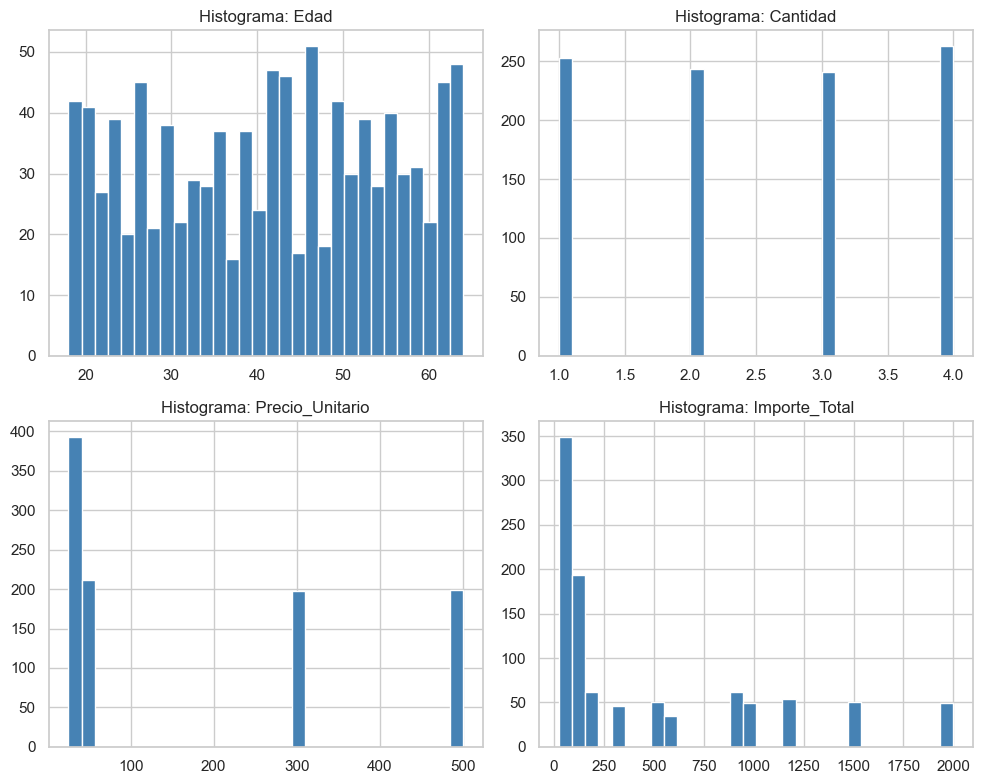

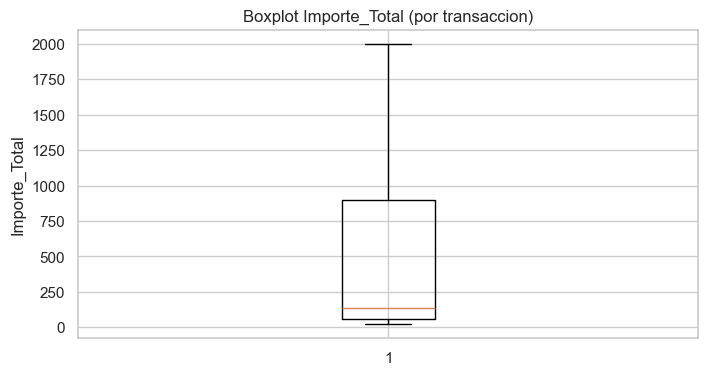

In [16]:
fig, axes = plt.subplots(2, 2, figsize=(10, 8))
for ax, col in zip(axes.ravel(), numericas):
    df[col].hist(bins=30, ax=ax, color="steelblue", edgecolor="white")
    ax.set_title(f"Histograma: {col}")
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(8, 4))
ax.boxplot(df["Importe_Total"], vert=True)
ax.set_title("Boxplot Importe_Total (por transaccion)")
ax.set_ylabel("Importe_Total")
plt.show()


### 4.3 Bivariado: correlacion entre numericas

Pregunta: que tan alineadas estan `Cantidad`, `Precio_Unitario` e `Importe_Total`?


,Edad,Cantidad,Precio_Unitario,Importe_Total
Edad,1.000,-0.024,-0.038,-0.061
Cantidad,-0.024,1.000,0.018,0.374
Precio_Unitario,-0.038,0.018,1.000,0.852
Importe_Total,-0.061,0.374,0.852,1.000


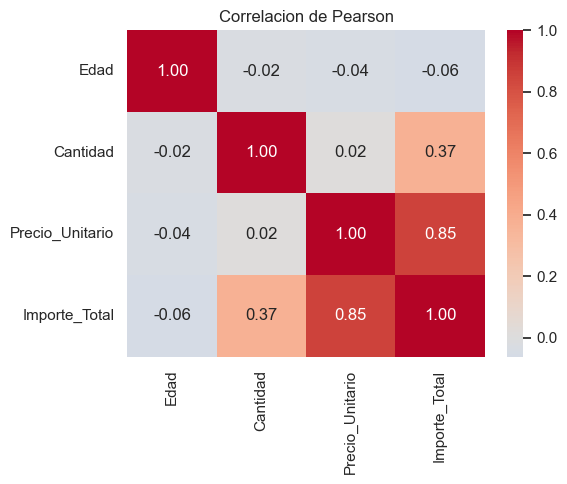

In [17]:
cm = df[numericas].corr(numeric_only=True)
display(cm.round(3))

fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax)
ax.set_title("Correlacion de Pearson")
plt.tight_layout()
plt.show()


### 4.4 Bivariado: categoricas (tablas cruzadas)

Pregunta: el mix de `Categoria_Producto` se parece entre `Genero`? Conteos y proporciones por fila.


In [18]:
ct = pd.crosstab(df["Genero"], df["Categoria_Producto"], margins=True)
print("Conteos Genero x Categoria_Producto:")
display(ct)

print("\nProporciones dentro de cada genero (filas suman 1):")
display(pd.crosstab(df["Genero"], df["Categoria_Producto"], normalize="index").round(3))


Conteos Genero x Categoria_Producto:


Categoria_Producto,Belleza,Electronica,Ropa,All
Genero,,,,
Femenino,166,170,174,510
Masculino,141,172,177,490
All,307,342,351,1000



Proporciones dentro de cada genero (filas suman 1):


Categoria_Producto,Belleza,Electronica,Ropa
Genero,,,
Femenino,0.325,0.333,0.341
Masculino,0.288,0.351,0.361


### 4.5 Bivariado: Importe_Total segun categoria y genero

Totales y promedios por categoria; boxplot cruzado; dispersion Cantidad vs Importe_Total.


,Categoria_Producto,n,importe_suma,importe_promedio
1,Electronica,342,156905,458.786550
2,Ropa,351,155580,443.247863
0,Belleza,307,143515,467.475570


C:\Users\owoc9\AppData\Local\Temp\ipykernel_57480\4052165530.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=por_cat, x="Categoria_Producto", y="importe_suma", ax=axes[0], palette="viridis")
C:\Users\owoc9\AppData\Local\Temp\ipykernel_57480\4052165530.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=por_cat, x="Categoria_Producto", y="importe_promedio", ax=axes[1], palette="mako")


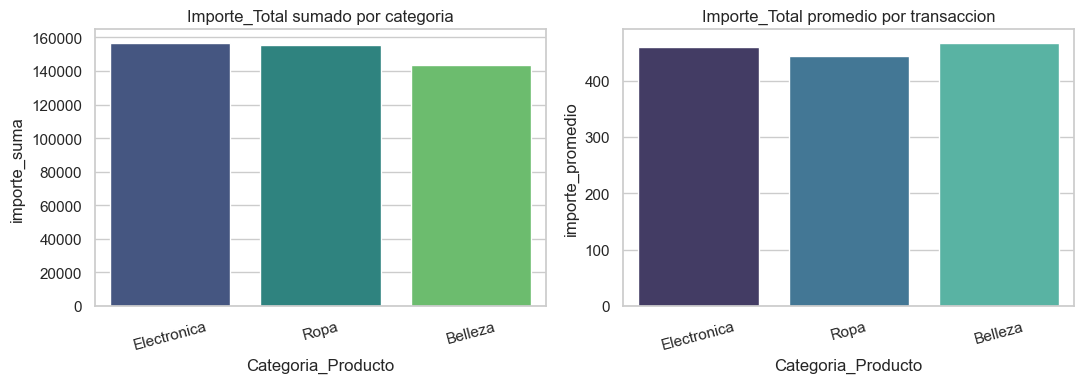

In [19]:
por_cat = (
    df.groupby("Categoria_Producto", as_index=False)
    .agg(
        n=("ID_Transaccion", "count"),
        importe_suma=("Importe_Total", "sum"),
        importe_promedio=("Importe_Total", "mean"),
    )
    .sort_values("importe_suma", ascending=False)
)
display(por_cat)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.barplot(data=por_cat, x="Categoria_Producto", y="importe_suma", ax=axes[0], palette="viridis")
axes[0].set_title("Importe_Total sumado por categoria")
axes[0].tick_params(axis="x", rotation=15)
sns.barplot(data=por_cat, x="Categoria_Producto", y="importe_promedio", ax=axes[1], palette="mako")
axes[1].set_title("Importe_Total promedio por transaccion")
axes[1].tick_params(axis="x", rotation=15)
plt.tight_layout()
plt.show()


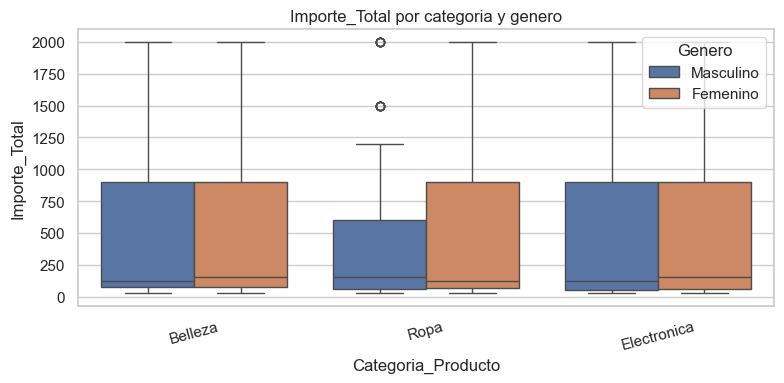

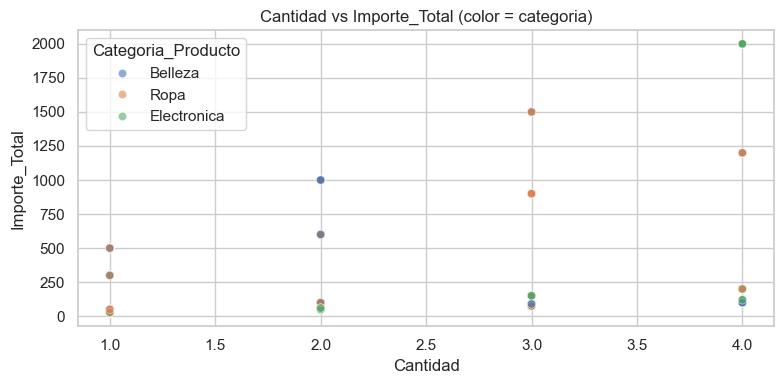

In [20]:
fig, ax = plt.subplots(figsize=(8, 4))
sns.boxplot(data=df, x="Categoria_Producto", y="Importe_Total", hue="Genero", ax=ax)
ax.set_title("Importe_Total por categoria y genero")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(8, 4))
sns.scatterplot(
    data=df,
    x="Cantidad",
    y="Importe_Total",
    hue="Categoria_Producto",
    alpha=0.6,
    ax=ax,
)
ax.set_title("Cantidad vs Importe_Total (color = categoria)")
plt.tight_layout()
plt.show()


### 4.6 Bivariado: Edad vs categorias

Distribucion de `Edad` segun `Genero` y segun `Categoria_Producto` (comparar medianas y dispersion).


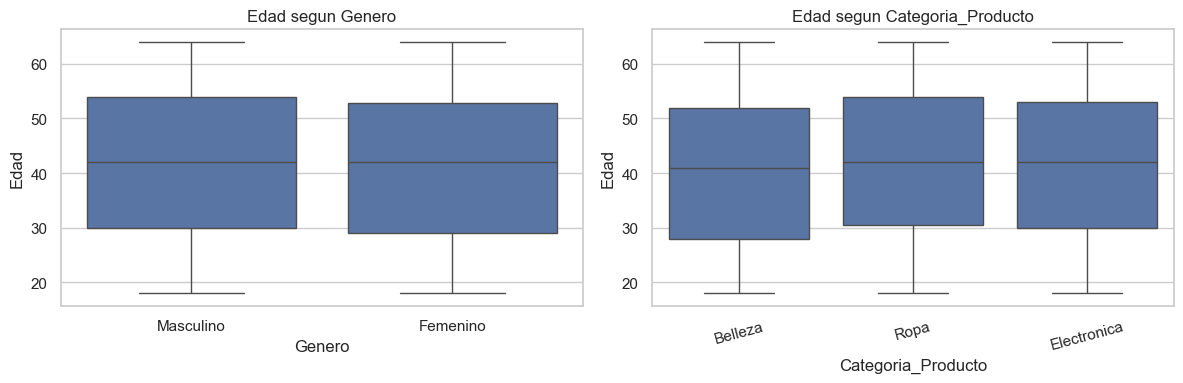

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.boxplot(data=df, x="Genero", y="Edad", ax=axes[0])
axes[0].set_title("Edad segun Genero")
sns.boxplot(data=df, x="Categoria_Producto", y="Edad", ax=axes[1])
axes[1].set_title("Edad segun Categoria_Producto")
axes[1].tick_params(axis="x", rotation=15)
plt.tight_layout()
plt.show()


### 4.7 Rankings de clientes (complemento)

Top por frecuencia de compra, por monto acumulado y por precio unitario (maximo en una linea).


In [25]:
df.columns

Index(['ID_Transaccion', 'Fecha', 'ID_Cliente', 'Genero', 'Edad',
       'Categoria_Producto', 'Cantidad', 'Precio_Unitario', 'Importe_Total'],
      dtype='str')

In [27]:
N_TOP = 15

frec_por_cliente = (
    df.groupby("ID_Cliente", as_index=False)
    .agg(num_transacciones=("Cantidad", "sum"))
    .sort_values("num_transacciones", ascending=False)
)
monto_por_cliente = (
    df.groupby("ID_Cliente", as_index=False)
    .agg(importe_total=("Importe_Total", "sum"), num_transacciones=("Cantidad", "sum"))
    .sort_values("importe_total", ascending=False)
)
print(f"Top {N_TOP} por transacciones:")
display(frec_por_cliente.head(N_TOP))
print(f"\nTop {N_TOP} por Importe_Total acumulado:")
display(monto_por_cliente.head(N_TOP))

max_pu = (
    df.groupby("ID_Cliente", as_index=False)
    .agg(max_importe_total=("Importe_Total", "max"), prom_importe_total=("Importe_Total", "mean"))
    .sort_values("max_importe_total", ascending=False)
)
print(f"\nTop {N_TOP} por mayor PrecioImporte_Total en una linea:")
display(max_pu.head(N_TOP))


Top 15 por transacciones:


,ID_Cliente,num_transacciones
7,CUST008,4
9,CUST010,4
13,CUST014,4
726,CUST726,4
729,CUST729,4
731,CUST731,4
735,CUST735,4
736,CUST736,4
740,CUST740,4
22,CUST023,4



Top 15 por Importe_Total acumulado:


,ID_Cliente,importe_total,num_transacciones
14,CUST015,2000,4
412,CUST412,2000,4
970,CUST970,2000,4
547,CUST547,2000,4
281,CUST281,2000,4
416,CUST416,2000,4
420,CUST420,2000,4
927,CUST927,2000,4
447,CUST447,2000,4
342,CUST342,2000,4



Top 15 por mayor PrecioImporte_Total en una linea:


,ID_Cliente,max_importe_total,prom_importe_total
14,CUST015,2000,2000.0
412,CUST412,2000,2000.0
970,CUST970,2000,2000.0
547,CUST547,2000,2000.0
281,CUST281,2000,2000.0
416,CUST416,2000,2000.0
420,CUST420,2000,2000.0
927,CUST927,2000,2000.0
447,CUST447,2000,2000.0
342,CUST342,2000,2000.0


## 5. Funcion `ModeloRFM_retail`

Misma estructura que `ModeloRFM` del cuaderno de clase:

- **Recencia:** dias entre la fecha de corte (`ultima fecha en datos + 1 dia`) y la ultima compra del cliente.
- **Frecuencia:** numero de transacciones (conteo de filas) por cliente en el subconjunto filtrado.
- **Monto:** suma de `Importe_Total`.
- **Scores R, F, M (1-5):** percentiles como en el modelo original (`Rscore` invertido para recencia; `FMScore` para F y M).
- **RFM ponderado:** `R*peso_R + F*peso_F + M*peso_M`.
- **Segmentos:** `General_Segment` (Diamante / Oro / Plata / Bronce) y `Segment` (Perdidos, En Riesgo, Estrella, etc.).

Parametros: `df`, `categoria` (`"TODOS"` o un valor de `Categoria_Producto`), `peso_R`, `peso_F`, `peso_M`.

In [ ]:
def clasificar_generacion(edad):
    if edad < 18:
        return "Menor de edad"
    elif 18 <= edad <= 27:
        return "Generacion Z"
    elif 28 <= edad <= 43:
        return "Millennial"
    elif 44 <= edad <= 59:
        return "Generacion X"
    elif 60 <= edad <= 78:
        return "Baby Boomer"
    else:
        return "Generacion Silenciosa"


def ModeloRFM_retail(df, categoria, peso_R, peso_F, peso_M):
    """
    categoria: 'TODOS' o un valor de la columna Categoria_Producto (ej. Belleza, Ropa, Electronica).
    """
    if categoria == "TODOS":
        df2 = df.copy()
    else:
        df2 = df[df["Categoria_Producto"] == categoria].reset_index(drop=True)

    if df2.empty:
        raise ValueError(f"No hay datos para la categoria: {categoria!r}")

    snapshot_date = df2["Fecha"].max() + dt.timedelta(days=1)

    df_rfm = df2.groupby("ID_Cliente", as_index=False).agg(
        Fecha=("Fecha", "max"),
        Frecuencia=("Cantidad", "sum"),
        Monto=("Importe_Total", "sum"),
        cliente_genero=("Genero", "first"),
        cliente_edad=("Edad", "first"),
    )

    df_rfm["Recencia"] = (snapshot_date - df_rfm["Fecha"]).dt.days
    df_rfm = df_rfm.drop(columns=["Fecha"])

    df_rfm["Generacion"] = df_rfm["cliente_edad"].apply(clasificar_generacion)

    df_rfm["RANK_R"] = df_rfm["Recencia"].rank(pct=True)
    df_rfm["RANK_F"] = df_rfm["Frecuencia"].rank(pct=True)
    df_rfm["RANK_M"] = df_rfm["Monto"].rank(pct=True)

    def Rscore(x):
        if x <= 0.2:
            return 5
        if x <= 0.4:
            return 4
        if x <= 0.6:
            return 3
        if x <= 0.8:
            return 2
        return 1

    def FMScore(x):
        if x <= 0.2:
            return 1
        if x <= 0.4:
            return 2
        if x <= 0.6:
            return 3
        if x <= 0.8:
            return 4
        return 5

    df_rfm["R"] = df_rfm["RANK_R"].apply(Rscore)
    df_rfm["F"] = df_rfm["RANK_F"].apply(FMScore)
    df_rfm["M"] = df_rfm["RANK_M"].apply(FMScore)

    df_rfm["RFM_nivel"] = (
        df_rfm["R"] * peso_R + df_rfm["F"] * peso_F + df_rfm["M"] * peso_M
    )

    def segment_me(bd):
        if bd["RFM_nivel"] >= 4.2:
            return "Diamante"
        if bd["RFM_nivel"] >= 3.1:
            return "Oro"
        if bd["RFM_nivel"] >= 1.9:
            return "Plata"
        return "Bronce"

    def new_segment(bd):
        if (bd["R"] <= 2) and (bd["F"] <= 2):
            return "Perdidos"
        if (1 <= bd["R"] <= 2) and (3 <= bd["F"] <= 4):
            return "En Riesgo"
        if (1 <= bd["R"] <= 2) and (bd["F"] == 5):
            return "Proximos a Perder"
        if (bd["R"] == 3) and (1 <= bd["F"] <= 2):
            return "En Duda"
        if (bd["R"] == 3) and (bd["F"] == 3):
            return "Necesita Atencion"
        if (3 <= bd["R"] <= 4) and (4 <= bd["F"] <= 5):
            return "Leales"
        if (bd["R"] == 4) and (bd["F"] == 1):
            return "Promesa"
        if (bd["R"] == 5) and (bd["F"] == 1):
            return "Nuevos"
        if (4 <= bd["R"] <= 5) and (2 <= bd["F"] <= 3):
            return "Leales Potenciales"
        if (bd["R"] == 5) and (4 <= bd["F"] <= 5):
            return "Estrella"
        return "Vacio"

    df_rfm["General_Segment"] = df_rfm.apply(segment_me, axis=1)
    df_rfm["Segment"] = df_rfm.apply(new_segment, axis=1)
    df_rfm["Producto"] = categoria

    return df_rfm

## 6. Ejecucion: mismos pesos que en el ejemplo de clase

En el cuaderno modelo se usa algo como `ModeloRFM(data, "ENVIO GIROS", 0.1, 0.3, 0.6)` (mas peso al monto). Aqui aplicamos **`TODOS`** los productos con los mismos pesos **0.1, 0.3, 0.6** (suman **1.0**; puedes probar otras combinaciones si el taller lo pide).

In [41]:
PESO_R, PESO_F, PESO_M = 0.1, 0.3, 0.6

rfm = ModeloRFM_retail(df, "TODOS", PESO_R, PESO_F, PESO_M)
print("Clientes unicos:", rfm.shape[0])
rfm.head(10)

Clientes unicos: 1000


,ID_Cliente,Frecuencia,Monto,cliente_genero,cliente_edad,Recencia,Generacion,RANK_R,RANK_F,RANK_M,R,F,M,RFM_nivel,General_Segment,Segment,Producto
0,CUST001,3,150,Masculino,34,39,Millennial,0.1100,0.617,0.5215,5,4,3,3.5,Oro,Estrella,TODOS
1,CUST002,2,1000,Femenino,26,309,Generacion Z,0.8455,0.375,0.8230,1,2,5,3.7,Oro,Perdidos,TODOS
2,CUST003,1,30,Masculino,50,354,Generacion X,0.9725,0.127,0.0770,1,1,1,1.0,Bronce,Perdidos,TODOS
3,CUST004,1,500,Masculino,37,226,Millennial,0.6070,0.127,0.6760,2,1,4,2.9,Plata,Perdidos,TODOS
4,CUST005,2,100,Masculino,30,241,Millennial,0.6590,0.375,0.4035,2,2,3,2.6,Plata,Perdidos,TODOS
5,CUST006,1,30,Femenino,45,252,Generacion X,0.6970,0.127,0.0770,2,1,1,1.1,Bronce,Perdidos,TODOS
6,CUST007,2,50,Masculino,46,295,Generacion X,0.8090,0.375,0.1600,1,2,1,1.3,Bronce,Perdidos,TODOS
7,CUST008,4,100,Masculino,30,314,Millennial,0.8600,0.869,0.4035,1,5,3,3.4,Oro,Proximos a Perder,TODOS
8,CUST009,2,600,Masculino,63,20,Baby Boomer,0.0520,0.375,0.7190,5,2,4,3.5,Oro,Leales Potenciales,TODOS
9,CUST010,4,200,Femenino,52,87,Generacion X,0.2435,0.869,0.5735,4,5,3,3.7,Oro,Leales,TODOS


## 7. Tablas de apoyo (como en el modelo de referencia)

In [42]:
print("Segmento general:")
print(rfm["General_Segment"].value_counts())
print("\nSubsegmento:")
print(rfm["Segment"].value_counts())

Segmento general:
General_Segment
Oro         349
Plata       281
Bronce      217
Diamante    153
Name: count, dtype: int64

Subsegmento:
Segment
Leales                203
Perdidos              199
Proximos a Perder     106
Estrella              101
En Duda               101
Leales Potenciales     99
En Riesgo              94
Nuevos                 50
Promesa                47
Name: count, dtype: int64


In [30]:
rfm.groupby("General_Segment", as_index=False).agg(
    clientes=("ID_Cliente", "count"), monto_total=("Monto", "sum")
)

,General_Segment,clientes,monto_total
0,Bronce,137,5420
1,Diamante,120,172000
2,Oro,320,236510
3,Plata,423,42070


## 8. Visualizaciones basicas

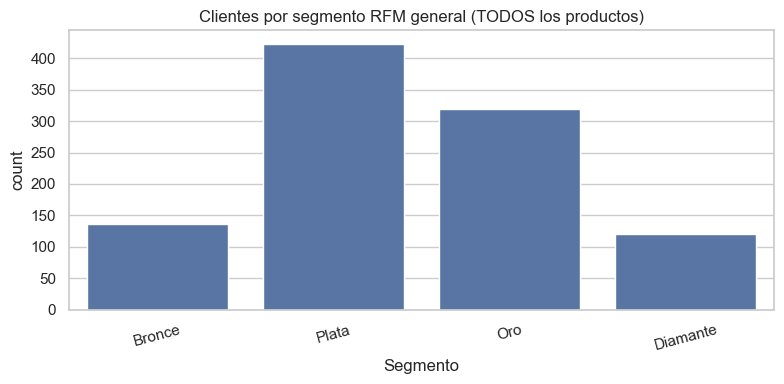

In [31]:
fig, ax = plt.subplots(figsize=(8, 4))
orden = ["Bronce", "Plata", "Oro", "Diamante"]
sns.countplot(data=rfm, x="General_Segment", order=[x for x in orden if x in rfm["General_Segment"].unique()], ax=ax)
ax.set_title("Clientes por segmento RFM general (TODOS los productos)")
ax.set_xlabel("Segmento")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

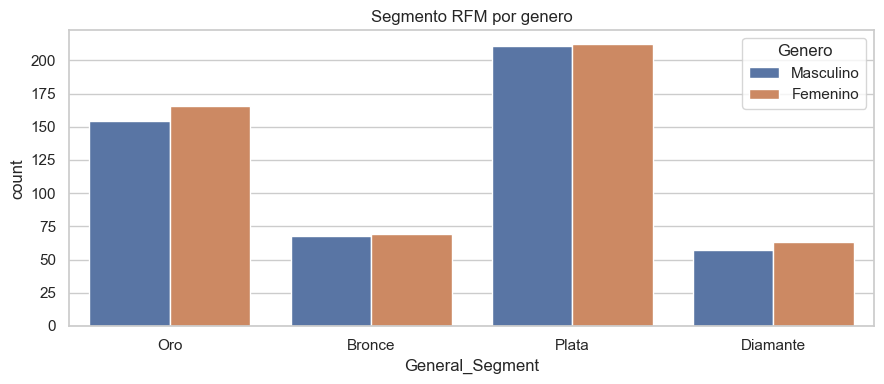

In [32]:
fig, ax = plt.subplots(figsize=(9, 4))
sns.countplot(data=rfm, x="General_Segment", hue="cliente_genero", ax=ax)
ax.set_title("Segmento RFM por genero")
plt.legend(title="Genero")
plt.tight_layout()
plt.show()

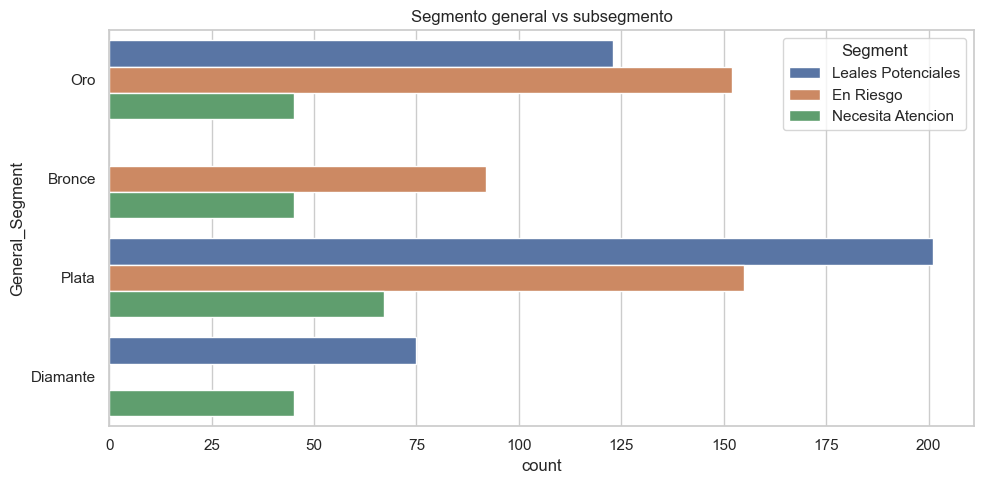

In [33]:
fig, ax = plt.subplots(figsize=(10, 5))
sns.countplot(data=rfm, y="General_Segment", hue="Segment", ax=ax)
ax.set_title("Segmento general vs subsegmento")
plt.tight_layout()
plt.show()

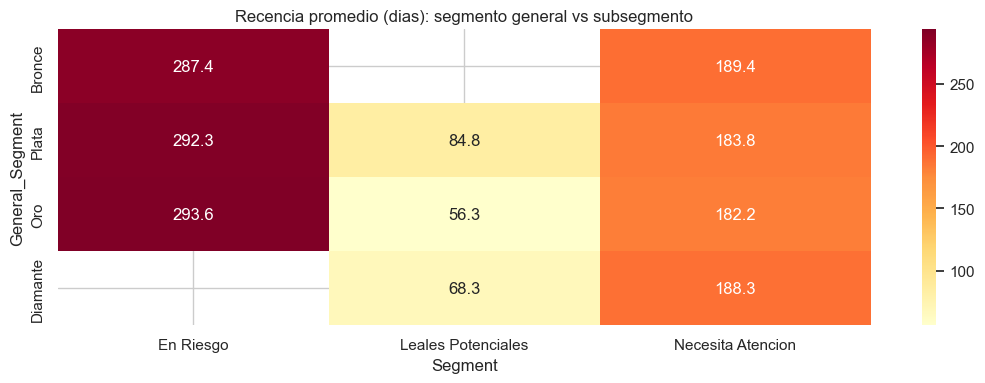

In [34]:
fig, ax = plt.subplots(figsize=(11, 4))
pivot = rfm.pivot_table(
    index="General_Segment",
    columns="Segment",
    values="Recencia",
    aggfunc="mean",
)
orden_f = ["Bronce", "Plata", "Oro", "Diamante"]
pivot = pivot.reindex([r for r in orden_f if r in pivot.index])
sns.heatmap(pivot, annot=True, fmt=".1f", cmap="YlOrRd", ax=ax)
ax.set_title("Recencia promedio (dias): segmento general vs subsegmento")
plt.tight_layout()
plt.show()

## 9. (Opcional) RFM por categoria de producto

Compara el comportamiento en **Belleza**, **Ropa** o **Electronica** cambiando el segundo argumento.

In [35]:
for cat in sorted(df["Categoria_Producto"].unique()):
    out = ModeloRFM_retail(df, cat, PESO_R, PESO_F, PESO_M)
    print(cat, "-> clientes:", out.shape[0])
    print(out["General_Segment"].value_counts().to_string())
    print()

Belleza -> clientes: 307
General_Segment
Plata       132
Oro          97
Diamante     40
Bronce       38

Electronica -> clientes: 342
General_Segment
Plata       146
Oro         105
Bronce       50
Diamante     41

Ropa -> clientes: 351
General_Segment
Plata       166
Oro         101
Bronce       46
Diamante     38



## 10. Analisis alternativo con nuevos pesos

En este punto repetimos la logica de los apartados 6 y 7, pero con una ponderacion mas agresiva hacia el **Monto**:

- `peso_R = 0.05`
- `peso_F = 0.15`
- `peso_M = 0.80`

La pregunta central es: **como cambia la segmentacion general y por categoria cuando el peso del gasto total domina el indice RFM?**

### 10.1 Ejecucion del modelo con los nuevos pesos

Primero ejecutamos nuevamente el modelo para **TODOS** los productos y luego para la categoria con mas transacciones.

In [ ]:
PESO_R_ALT, PESO_F_ALT, PESO_M_ALT = 0.05, 0.15, 0.80

rfm_alt = ModeloRFM_retail(df, "TODOS", PESO_R_ALT, PESO_F_ALT, PESO_M_ALT)
cat_foco_alt = df["Categoria_Producto"].value_counts().idxmax()
rfm_alt_foco = ModeloRFM_retail(df, cat_foco_alt, PESO_R_ALT, PESO_F_ALT, PESO_M_ALT)

print("Pesos alternativos:", PESO_R_ALT, PESO_F_ALT, PESO_M_ALT)
print("Categoria foco:", cat_foco_alt)
print("\nDistribucion general con pesos alternativos (TODOS):")
display(rfm_alt["General_Segment"].value_counts())
print("\nDistribucion general con pesos alternativos en la categoria foco:")
display(rfm_alt_foco["General_Segment"].value_counts())
print("\nPrimeras filas del nuevo RFM:")
rfm_alt.head(10)

### 10.2 Tablas de apoyo con los nuevos pesos

Repetimos las tablas clave del punto 7 y comparamos de forma directa los resultados con el escenario base (`0.10`, `0.30`, `0.60`).

In [ ]:
orden_general = ["Diamante", "Oro", "Plata", "Bronce"]

comparacion_general = pd.concat(
    [
        rfm["General_Segment"].value_counts().reindex(orden_general, fill_value=0).rename("Base_0_10_0_30_0_60"),
        rfm_alt["General_Segment"].value_counts().reindex(orden_general, fill_value=0).rename("Alt_0_05_0_15_0_80"),
    ],
    axis=1,
)
comparacion_general["Diferencia"] = (
    comparacion_general["Alt_0_05_0_15_0_80"] - comparacion_general["Base_0_10_0_30_0_60"]
)

comparacion_subsegmento = pd.concat(
    [
        rfm["Segment"].value_counts().rename("Base_0_10_0_30_0_60"),
        rfm_alt["Segment"].value_counts().rename("Alt_0_05_0_15_0_80"),
    ],
    axis=1,
).fillna(0)
comparacion_subsegmento["Diferencia"] = (
    comparacion_subsegmento["Alt_0_05_0_15_0_80"] - comparacion_subsegmento["Base_0_10_0_30_0_60"]
)
comparacion_subsegmento = comparacion_subsegmento.sort_values("Diferencia", ascending=False)

resumen_alt = rfm_alt.groupby("General_Segment", as_index=False).agg(
    clientes=("ID_Cliente", "count"), monto_total=("Monto", "sum")
)

print("Comparacion por segmento general:")
display(comparacion_general)
print("\nSubsegmentos que mas cambian:")
display(comparacion_subsegmento)
print("\nResumen del escenario alternativo:")
display(resumen_alt)

print("\nGenero en transacciones (df):")
display(df["Genero"].value_counts())
print("\nGenero en clientes RFM con pesos alternativos:")
display(rfm_alt["cliente_genero"].value_counts())

print("\nIndicadores agregados con pesos alternativos:")
print("Monto total (RFM alt):", float(rfm_alt["Monto"].sum()))
print("Numero de clientes (RFM alt):", rfm_alt.shape[0])
print("Transacciones promedio por cliente en df:", len(df) / df["ID_Cliente"].nunique())

### 10.3 y 10.4 Comparacion del analisis: escenario base vs escenario alternativo

Ahora comparamos directamente ambos esquemas de pesos, primero para **TODOS** los datos y despues por categoria de producto.

In [ ]:
def distrib_segmentos(df_rfm, orden):
    return df_rfm["General_Segment"].value_counts(normalize=True).reindex(orden, fill_value=0)

ambitos = ["TODOS"] + sorted(df["Categoria_Producto"].unique())
filas = []
resumen_ambitos = []

for ambito in ambitos:
    if ambito == "TODOS":
        base_rfm = rfm.copy()
        alt_rfm = rfm_alt.copy()
    else:
        base_rfm = ModeloRFM_retail(df, ambito, PESO_R, PESO_F, PESO_M)
        alt_rfm = ModeloRFM_retail(df, ambito, PESO_R_ALT, PESO_F_ALT, PESO_M_ALT)

    dist_base = distrib_segmentos(base_rfm, orden_general)
    dist_alt = distrib_segmentos(alt_rfm, orden_general)

    for seg in orden_general:
        filas.append(
            {
                "Ambito": ambito,
                "Segmento": seg,
                "Base_pct": dist_base[seg] * 100,
                "Alt_pct": dist_alt[seg] * 100,
                "Dif_pp": (dist_alt[seg] - dist_base[seg]) * 100,
            }
        )

    dif = (dist_alt - dist_base) * 100
    resumen_ambitos.append(
        {
            "Ambito": ambito,
            "Segmento_que_mas_sube": dif.idxmax(),
            "Cambio_max_pp": round(float(dif.max()), 2),
            "Segmento_que_mas_baja": dif.idxmin(),
            "Cambio_min_pp": round(float(dif.min()), 2),
        }
    )

comparacion_por_ambito = pd.DataFrame(filas)
resumen_ambitos = pd.DataFrame(resumen_ambitos)
pivot_dif = comparacion_por_ambito.pivot(index="Ambito", columns="Segmento", values="Dif_pp").round(2)

seg_mas_sube = comparacion_general["Diferencia"].idxmax()
seg_mas_baja = comparacion_general["Diferencia"].idxmin()
sube_sub = comparacion_subsegmento.index[0]
baja_sub = comparacion_subsegmento.index[-1]

print("Cambios en porcentaje de clientes por segmento (puntos porcentuales):")
display(pivot_dif)
print("\nResumen por ambito:")
display(resumen_ambitos)

print("Interpretacion automatica del caso general:")
print(f"- El segmento general que mas sube con los nuevos pesos es: {seg_mas_sube}.")
print(f"- El segmento general que mas baja con los nuevos pesos es: {seg_mas_baja}.")
print(f"- El subsegmento que mas aumenta es: {sube_sub}.")
print(f"- El subsegmento que mas disminuye es: {baja_sub}.")
print("- Como el peso del Monto aumenta a 0.80, los clientes de mayor gasto tienen mas influencia en la clasificacion final.")
print("- La tabla por ambito permite ver si ese efecto es uniforme o distinto entre Belleza, Ropa y Electronica.")